# 05outline: the outline of Spain, stretched like the cities (Madrid view)

**What it does:** warps the outline of mainland Spain for every era so that it moves with the cities on the radial time map from Madrid (04timemap). The outline is a backdrop: only the city positions are measured; the coast between them is interpolated.

- **Method.** Every outline point keeps its true bearing from Madrid, like the cities. Its distance from Madrid is multiplied by a stretch factor (map distance / real distance) that depends only on its bearing: a weighted mean of the cities' stretch factors, weighted by how close each city's bearing is. Then each city pushes the outline outward in its own direction so that no city ends up outside the coast: near a city's bearing, the outline stays at least a small margin beyond the city on the map (tapering off within a few degrees). A first version pushed the coast out by the city's full stretch, which threw the Castellon coast 600 km out to sea behind slow Teruel.
- **Inland cities.** In the blend, a city counts by how close it is to the coast in its own direction (weight x (distance to the city / distance to the coast beyond it) to a power). Otherwise a slow inland city sets the stretch of the coast behind it: Teruel (420 min in 1985 for 230 km) threw the Castellon coast 600 km out. Inland cities still keep the coast beyond themselves through the push rule.
- **Why bearing only.** A stretch that depends only on the direction is a plain radial zoom along each ray, so the outline cannot fold over itself along a ray. A per-point weighting by distance was tried first and left Teruel and Jaen outside the coast (inland cities behind fast coastal ones).
- **Repair.** Where the coast doubles back on itself (small capes such as Finisterre), a tiny loop can still appear. Loops spanning only a few outline points are collapsed onto their crossing point. Every era keeps the same number of points, so the page can morph the outline point by point.
- **Madrid only.** From a city near the edge (Huelva, Santander) the coast wraps round the centre and a bearing-only stretch fails (tested: 170 of 217 centre and era cases fold or lose a city). Recentred views on the page will use time rings instead of a warped outline.

**Input:** `data/clean/timemap_positions.csv` (04timemap), Natural Earth 1:10m Admin 0 countries (downloaded once to `data/raw/naturalearth/`).

**Output:** `data/clean/outline_madrid.csv` (era, point number, x and y in km on the Madrid map; era "real" = the true outline), `figures/05outline.png`.

**Data credit:** outline from Natural Earth (public domain), naturalearthdata.com, via the nvkelso/natural-earth-vector repository. Travel times as in 04timemap.

## 0. Settings

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from matplotlib.path import Path as PolyPath

POSITIONS_CSV = Path("data") / "clean" / "timemap_positions.csv"
ACCESS_CSV = Path("data") / "raw" / "manual" / "access_2025.csv"
NE_DIR = Path("data") / "raw" / "naturalearth"
NE_FILE = NE_DIR / "ne_10m_admin_0_countries.geojson"
NE_URL = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_10m_admin_0_countries.geojson"
OUT_CSV = Path("data") / "clean" / "outline_madrid.csv"
FIG_DIR = Path("figures")
COUNTRY = "ESP"  # <- Natural Earth ADM0_A3 code
CENTRE = "Madrid"  # <- centre of the map (the warp only works for a central city)
EARTH_RADIUS_KM = 6371.0
POWER = 2  # <- weighting of cities by bearing difference: 1 / (difference + SOFT_DEG) ** POWER
SOFT_DEG = 2.0  # <- degrees added to every bearing difference (higher = smoother, less local)
WINDOW_DEG = 15.0  # <- each city pushes the outline outward within this many degrees of its bearing
COAST_WEIGHT_POWER = 8  # <- inland cities count less in the blend: weight x (distance to city / distance to the coast beyond it) ** this (0 = all equal)
MARGIN_KM = 25.0  # <- the outline stays at least this far beyond each city in the city's own direction (on the map)
MAX_LOOP_POINTS = 40  # <- loops spanning at most this many outline points are collapsed
COAST_TOLERANCE_KM = 2.0  # <- a city this close outside the warped outline counts as on the coast (ports such as Vigo)
COLOUR = {"hub": "#3a3a3a", "full": "#1d6fa5", "part": "#b8860b", "none": "#c2410c"}  # <- VISUAL: as in 04timemap
LAND_COLOUR = "#eef1f4"  # <- VISUAL: fill of the warped outline
COAST_COLOUR = "#9aa5b1"  # <- VISUAL: line of the warped outline
REAL_COAST_COLOUR = "#dddddd"  # <- VISUAL: real outline behind the warped one
FIG_EXTENT_KM = 620  # <- VISUAL: half width of each panel

## 1. Read the city positions (from 04timemap)

In [2]:
positions = pd.read_csv(POSITIONS_CSV)
madrid = positions[positions["centre"] == CENTRE]
ERAS = list(dict.fromkeys(madrid["era"].astype(str)))
names = list(madrid[madrid["era"].astype(str) == ERAS[0]]["city"])
access = pd.read_csv(ACCESS_CSV)
group = dict(zip(access["city"], access["access"]))
group[CENTRE] = "hub"

others = madrid[madrid["city"] != CENTRE]
scale = np.hypot(others["x_km"], others["y_km"]) / others["minutes"]
KM_PER_MIN = float(scale.median())
print(f"eras: {ERAS}")
print(f"{len(names)} cities; scale from 04timemap: 1 min = {KM_PER_MIN:.3f} km (spread {scale.min():.3f} to {scale.max():.3f}, rounding only)")

eras: ['1985', '1993', '2001', '2010', '2018', '2025', '2026']
32 cities; scale from 04timemap: 1 min = 0.994 km (spread 0.994 to 0.994, rounding only)


## 2. The real outline of mainland Spain

In [3]:
NE_DIR.mkdir(parents=True, exist_ok=True)
if not NE_FILE.exists():
    response = requests.get(NE_URL, timeout=120)
    response.raise_for_status()
    NE_FILE.write_bytes(response.content)
    print(f"downloaded {NE_FILE} ({len(response.content) / 1e6:.1f} MB)")
countries = json.loads(NE_FILE.read_text(encoding="utf-8"))
feature = [f for f in countries["features"] if f["properties"]["ADM0_A3"] == COUNTRY][0]
polygons = feature["geometry"]["coordinates"]
mainland = max(polygons, key=lambda p: len(p[0]))
ring = np.array(mainland[0])
if np.allclose(ring[0], ring[-1]):
    ring = ring[:-1]
print(f"{feature['properties']['NAME']}: {len(polygons)} polygons; mainland outer ring {len(ring)} points (islands left out, like the cities)")

downloaded data\raw\naturalearth\ne_10m_admin_0_countries.geojson (13.3 MB)
Spain: 23 polygons; mainland outer ring 2157 points (islands left out, like the cities)


## 3. Project from Madrid and check the cities against the real outline

Same azimuthal equidistant projection as 04timemap: true bearing and distance from Madrid. A few coastal stations sit just outside the 1:10m coastline (the line is generalised); they are left out of the "inside" check later, since they were never inside.

In [4]:
def project(lat0, lon0, lat, lon):
    """x, y in km on an azimuthal equidistant projection centred on (lat0, lon0)."""
    p0 = np.radians(lat0)
    p1 = np.radians(lat)
    dl = np.radians(lon - lon0)
    bearing = np.arctan2(np.sin(dl) * np.cos(p1), np.cos(p0) * np.sin(p1) - np.sin(p0) * np.cos(p1) * np.cos(dl))
    h = np.sin((p1 - p0) / 2) ** 2 + np.cos(p0) * np.cos(p1) * np.sin(dl / 2) ** 2
    distance = 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(h))
    return np.column_stack([distance * np.sin(bearing), distance * np.cos(bearing)])

real_cities = madrid[madrid["era"].astype(str) == ERAS[0]].set_index("city").loc[names, ["real_x_km", "real_y_km"]].to_numpy()
centre_xy = real_cities[names.index(CENTRE)]
cities_csv = pd.read_csv(Path("data") / "clean" / "cities.csv").set_index("city")
outline_real = project(cities_csv.loc[CENTRE, "lat"], cities_csv.loc[CENTRE, "lon"], ring[:, 1], ring[:, 0])
print(f"Madrid at ({centre_xy[0]:.3f}, {centre_xy[1]:.3f}) km (should be 0, 0)")
inside_real = PolyPath(outline_real).contains_points(real_cities)
print("cities just outside the real 1:10m coastline:", [n for n, ok in zip(names, inside_real) if not ok])

Madrid at (0.000, 0.000) km (should be 0, 0)
cities just outside the real 1:10m coastline: ['Málaga', 'Santander']


## 4. Stretch the outline for every era

In [5]:
def bearing_deg(xy):
    return np.degrees(np.arctan2(xy[:, 0], xy[:, 1])) % 360

def bearing_gap(a, b):
    return np.abs((a[:, None] - b[None, :] + 180) % 360 - 180)

def self_crossings(points):
    """Pairs (i, j) of outline segments that cross each other (segment i runs from point i to point i + 1)."""
    n = len(points)
    start = points
    end = np.roll(points, -1, axis=0)
    def side(p, q, r):
        return (q[..., 0] - p[..., 0]) * (r[..., 1] - p[..., 1]) - (q[..., 1] - p[..., 1]) * (r[..., 0] - p[..., 0])
    pairs = []
    for i in range(n):
        j = np.arange(i + 2, n) if i > 0 else np.arange(2, n - 1)
        d1 = side(start[i], end[i], start[j])
        d2 = side(start[i], end[i], end[j])
        d3 = side(start[j], end[j], start[i])
        d4 = side(start[j], end[j], end[i])
        for jj in j[(d1 * d2 < 0) & (d3 * d4 < 0)]:
            pairs.append((i, int(jj)))
    return pairs

def distance_to_outline(point, shape):
    start = shape
    end = np.roll(shape, -1, axis=0)
    step = end - start
    length2 = (step * step).sum(axis=1)
    t = np.where(length2 > 0, ((point - start) * step).sum(axis=1) / np.where(length2 > 0, length2, 1), 0)
    t = np.clip(t, 0, 1)
    nearest = start + t[:, None] * step
    return float(np.hypot(nearest[:, 0] - point[0], nearest[:, 1] - point[1]).min())

def repair_loops(points):
    """Collapse small loops onto their crossing point; the number of points stays the same."""
    points = points.copy()
    collapsed = 0
    for _ in range(20):
        pairs = [(i, j) for i, j in self_crossings(points) if j - i <= MAX_LOOP_POINTS]
        if not pairs:
            break
        i, j = pairs[0]
        p = points[i]
        r = points[(i + 1) % len(points)] - p
        q = points[j]
        s = points[(j + 1) % len(points)] - q
        t = ((q[0] - p[0]) * s[1] - (q[1] - p[1]) * s[0]) / (r[0] * s[1] - r[1] * s[0])
        points[i + 1:j + 1] = p + t * r
        collapsed += j - i
    return points, collapsed

city_bearing = bearing_deg(real_cities)
city_distance = np.hypot(real_cities[:, 0], real_cities[:, 1])
outline_bearing = bearing_deg(outline_real)
outline_distance = np.hypot(outline_real[:, 0], outline_real[:, 1])
not_centre = np.array([n != CENTRE for n in names])
near = bearing_gap(outline_bearing, city_bearing[not_centre]) < 2.0
beyond = near & (outline_distance[:, None] > city_distance[not_centre][None, :])
coast_distance = np.where(beyond, outline_distance[:, None], np.inf).min(axis=0)  # real distance from Madrid to the nearest coast beyond each city, in its direction (within 2 degrees)
print("real distance to the coast in each city's direction (km):", dict(zip(np.array(names)[not_centre], coast_distance.round(0))))
gap = bearing_gap(outline_bearing, city_bearing[not_centre])
closeness = (city_distance[not_centre] / coast_distance) ** COAST_WEIGHT_POWER  # 1 for a city on the coast, small for one far inland
weight = closeness[None, :] / (gap + SOFT_DEG) ** POWER
print("coast weight per city:", {n: round(float(w), 2) for n, w in zip(np.array(names)[not_centre], closeness)})
taper = np.where(gap < WINDOW_DEG, np.cos(np.pi * gap / (2 * WINDOW_DEG)) ** 2, 0)

outlines = {"real": outline_real}
city_maps = {"real": real_cities}
rows = []
for era in ERAS:
    p = madrid[madrid["era"].astype(str) == era].set_index("city").loc[names]
    city_map = p[["x_km", "y_km"]].to_numpy()
    stretch = KM_PER_MIN * p["minutes"].to_numpy()[not_centre] / city_distance[not_centre]
    blended = (weight * stretch).sum(axis=1) / weight.sum(axis=1)
    city_radius = KM_PER_MIN * p["minutes"].to_numpy()[not_centre]
    needed = (city_radius + MARGIN_KM) / coast_distance  # stretch that puts the coast just beyond the city, in the city's direction
    pushed = (taper * needed).max(axis=1)
    factor = np.maximum(blended, pushed)
    warped = outline_real * factor[:, None]
    loops_before = len(self_crossings(warped))
    warped, collapsed = repair_loops(warped)
    loops_after = len(self_crossings(warped))
    inside = PolyPath(warped).contains_points(city_map)
    outside = [(n, distance_to_outline(xy, warped)) for n, xy, was, now in zip(names, city_map, inside_real, inside) if was and not now]
    lost = [f"{n} ({d:.1f} km)" for n, d in outside if d > COAST_TOLERANCE_KM]
    on_coast = [f"{n} ({d:.1f} km)" for n, d in outside if d <= COAST_TOLERANCE_KM]
    area = 0.5 * abs(np.dot(warped[:, 0], np.roll(warped[:, 1], 1)) - np.dot(warped[:, 1], np.roll(warped[:, 0], 1)))
    rows.append({"era": era, "crossings_before": loops_before, "points_collapsed": collapsed, "crossings_after": loops_after, "cities_lost": ", ".join(lost), "on_coast": ", ".join(on_coast), "area_km2": round(area)})
    outlines[era] = warped
    city_maps[era] = city_map

real_area = 0.5 * abs(np.dot(outline_real[:, 0], np.roll(outline_real[:, 1], 1)) - np.dot(outline_real[:, 1], np.roll(outline_real[:, 0], 1)))
checks = pd.DataFrame(rows)
checks["area_share"] = (checks["area_km2"] / real_area).round(2)
print(f"real mainland area on the projection: {real_area:,.0f} km2 (official mainland Spain: about 493,000 km2)")
print(checks.to_string(index=False))

real distance to the coast in each city's direction (km): {np.str_('Sevilla'): np.float64(443.0), np.str_('Córdoba'): np.float64(470.0), np.str_('Ciudad Real'): np.float64(411.0), np.str_('Cádiz'): np.float64(487.0), np.str_('Málaga'): np.float64(416.0), np.str_('Granada'): np.float64(407.0), np.str_('Zaragoza'): np.float64(484.0), np.str_('Lleida'): np.float64(601.0), np.str_('Tarragona'): np.float64(449.0), np.str_('Barcelona'): np.float64(503.0), np.str_('Girona'): np.float64(598.0), np.str_('Valencia'): np.float64(304.0), np.str_('Albacete'): np.float64(363.0), np.str_('Alicante'): np.float64(359.0), np.str_('Murcia'): np.float64(381.0), np.str_('Valladolid'): np.float64(412.0), np.str_('León'): np.float64(412.0), np.str_('Oviedo'): np.float64(398.0), np.str_('Ourense'): np.float64(489.0), np.str_('Santiago'): np.float64(536.0), np.str_('A Coruña'): np.float64(510.0), np.str_('Vigo'): np.float64(466.0), np.str_('Badajoz'): np.float64(331.0), np.str_('Teruel'): np.float64(336.0), np

**Reading the checks:** `crossings_after` must be 0 and `cities_lost` empty in every era. `on_coast` lists cities that end up just outside the warped line by at most `COAST_TOLERANCE_KM` (ports in narrow inlets, such as Vigo in its ria): they sit on the coast, which is fine. `area_share` is the area inside the warped outline as a share of the real one. It is illustrative only: the coast between cities is interpolated, so this number depends on the method, not just on the timetables. Do not use it as a headline figure.

## 5. Figure (draft for checking)

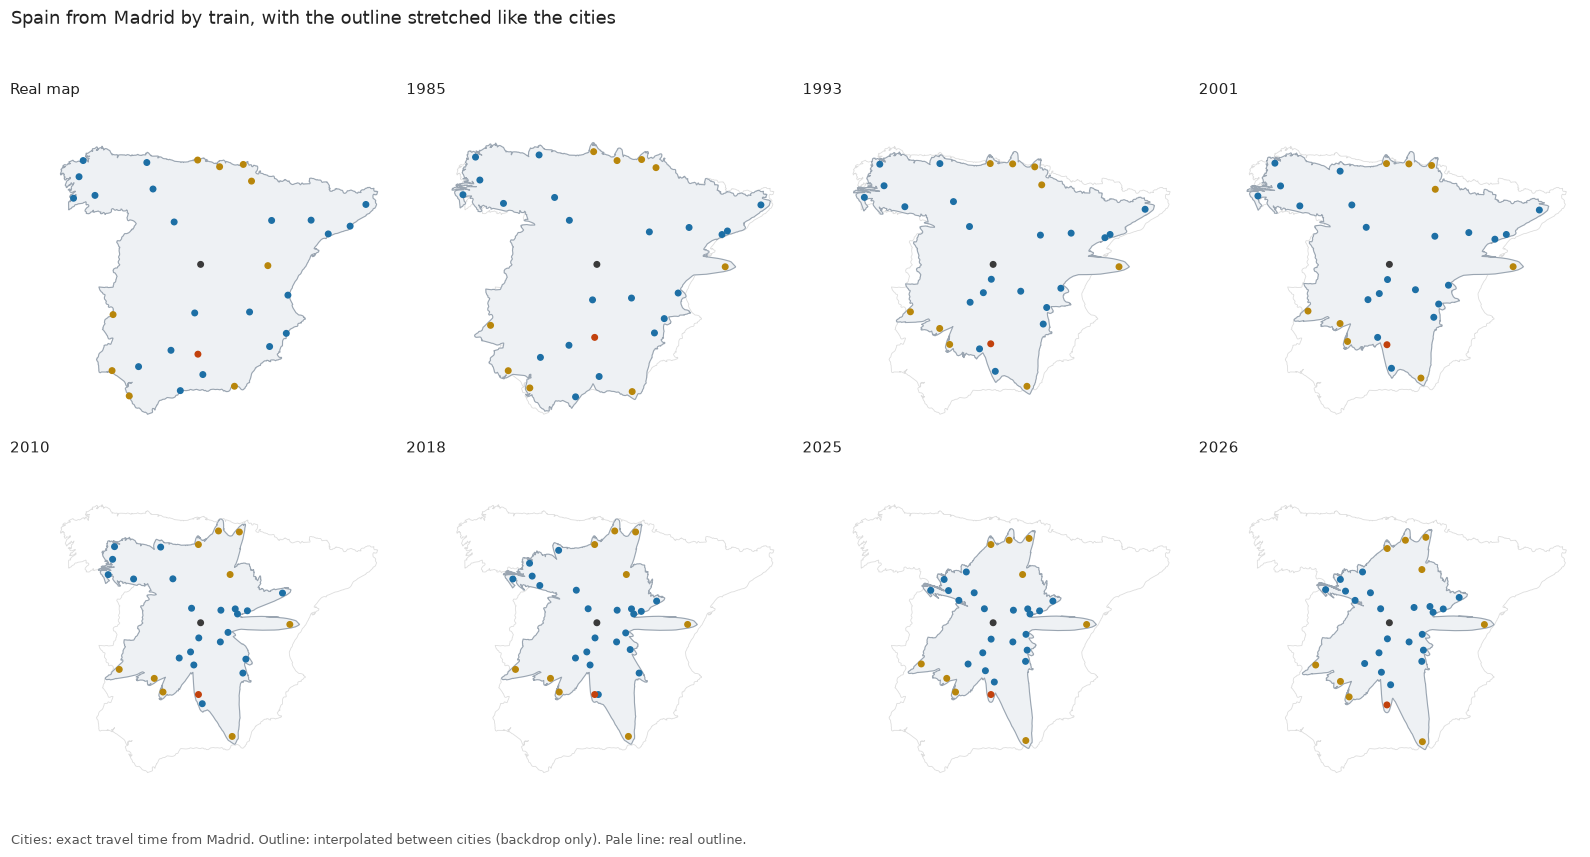

In [6]:
FIG_DIR.mkdir(exist_ok=True)
fig, axes = plt.subplots(2, 4, figsize=(16, 8.6))
for ax, era in zip(axes.flat, ["real"] + ERAS):
    shape = outlines[era]
    closed = np.vstack([shape, shape[:1]])
    if era != "real":
        real_closed = np.vstack([outline_real, outline_real[:1]])
        ax.plot(real_closed[:, 0], real_closed[:, 1], color=REAL_COAST_COLOUR, lw=0.6, zorder=0)
    ax.fill(shape[:, 0], shape[:, 1], color=LAND_COLOUR, zorder=1)
    ax.plot(closed[:, 0], closed[:, 1], color=COAST_COLOUR, lw=0.8, zorder=2)
    cm = city_maps[era]
    ax.scatter(cm[:, 0], cm[:, 1], s=16, c=[COLOUR[group[n]] for n in names], zorder=3)
    ax.set_xlim(-FIG_EXTENT_KM, FIG_EXTENT_KM)
    ax.set_ylim(-FIG_EXTENT_KM * 0.85, FIG_EXTENT_KM * 0.85)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title("Real map" if era == "real" else era, loc="left", fontsize=11, color="#222222")
fig.suptitle("Spain from Madrid by train, with the outline stretched like the cities", x=0.01, ha="left", fontsize=13, color="#222222")
fig.text(0.01, 0.01, "Cities: exact travel time from Madrid. Outline: interpolated between cities (backdrop only). Pale line: real outline.", fontsize=9, color="#555555")
plt.tight_layout(rect=(0, 0.02, 1, 0.97))
plt.savefig(FIG_DIR / "05outline.png", dpi=130)
plt.show()

## 6. Save the outlines

In [7]:
parts = []
for era, shape in outlines.items():
    part = pd.DataFrame({"era": era, "point": np.arange(len(shape)), "x_km": shape[:, 0].round(2), "y_km": shape[:, 1].round(2)})
    parts.append(part)
out = pd.concat(parts, ignore_index=True)
out.to_csv(OUT_CSV, index=False, encoding="utf-8")
print(f"saved {OUT_CSV}: {len(out)} rows ({len(outlines)} outlines x {len(outline_real)} points)")

saved data\clean\outline_madrid.csv: 17256 rows (8 outlines x 2157 points)


___
**END**